In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="oLoyIy4vuLxsybxNNoPT")
project = rf.workspace("noorbintahmd-gmail-com").project("bahraini-currency-coins")
version = project.version(4)
dataset = version.download("yolo26")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 32.1 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bahraini-Currency-Coins-4 in yolo26:: 100%|██████████| 840/840 [00:01<00:00, 832.65it/s]


In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [3]:
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),         # for size
    transforms.RandomRotation(30),         # for ميلان الصوره
    transforms.RandomAffine(0, scale=(0.5, 1.2)),   # for zome 50% into 120% and the 0 for not rotation
    transforms.RandomHorizontalFlip(),              # for flip the img
    transforms.ColorJitter(brightness=0.4),         # for light if dark or light 40%
    transforms.ToTensor(),                  # chang imge to numbers
    transforms.Normalize([0.5]*3, [0.5]*3),
])

In [4]:
test_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

In [7]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader

In [34]:
# i take it from ai to red the files
class MyDataset(Dataset):
    def __init__(self, root, split, transform=None, label_ext=".txt"):
        self.img_dir = os.path.join(root, split, "images")
        self.label_dir = os.path.join(root, split, "labels")
        self.files = sorted(f for f in os.listdir(self.img_dir)
                            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")))
        self.transform = transform
        self.label_ext = label_ext

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        name = self.files[idx]
        img = Image.open(os.path.join(self.img_dir, name)).convert("RGB")

        label_path = os.path.join(self.label_dir, os.path.splitext(name)[0] + self.label_ext)

        label = 0  # Default fallback label if file is empty
        if os.path.exists(label_path):
            with open(label_path) as f:
                content = f.read().split()
                if len(content) > 0:
                    label = int(content[0])

        if self.transform:
            img = self.transform(img)
        return img, label

In [17]:
root = "Bahraini-Currency-Coins-4"
train = MyDataset(root, "train", train_tf)

In [20]:
valid = MyDataset(root, "valid", train_tf)

In [37]:
test = MyDataset(root, "test", train_tf)

In [38]:
train_loader = DataLoader(train, shuffle=True)
val_loader = DataLoader(valid)
test_loader = DataLoader(test)

In [39]:
import torch
import torch.nn as nn
from torchvision import models

num_classes = 8
# ready model and change last lear
model = models.resnet18(weights="DEFAULT")
model.fc = nn.Linear(model.fc.in_features, num_classes)
# to see how many the model loss
criterion = nn.CrossEntropyLoss()
# to balence weights and reduce the wrong , lr for speed of learn
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [40]:
import numpy as np
import torch
from torch.utils.data import DataLoader

In [41]:
import numpy as np

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(next(model.parameters()).device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [43]:
print("Accuracy:", accuracy_score(y_true, y_pred))

Accuracy: 0.08333333333333333


In [44]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        12
           1       0.00      0.00      0.00        13
           2       0.00      0.00      0.00         2
           3       0.00      0.00      0.00        13
           4       0.00      0.00      0.00         2
           5       0.06      0.20      0.09         5
           6       0.12      0.36      0.18        11
           7       0.00      0.00      0.00         2

    accuracy                           0.08        60
   macro avg       0.02      0.07      0.03        60
weighted avg       0.03      0.08      0.04        60



Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


In [53]:
# for name of classes
with open("Bahraini-Currency-Coins-4/data.yaml") as f:
    class_names = yaml.safe_load(f)["names"]
print(class_names)

['1 BD', '10 BD', '100fils', '20 BD', '25fils', '5 BD', '500 fils', '50fils']


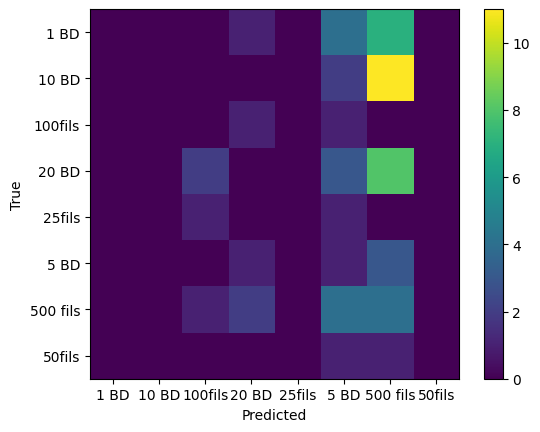

In [54]:
cm = confusion_matrix(y_true, y_pred)
plt.imshow(cm)
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(len(class_names)), class_names)
plt.yticks(range(len(class_names)), class_names)
plt.show()

In [56]:
import torch
torch.save(model.state_dict(), "model.pth")